# 03 — Negativos, features e treino do Random Forest
Reprodução: *Uma Proposta de Algoritmo para a Detecção de Mixers na Ethereum* (Leale & Sendin, SBSeg 2025).

| Parte | O que faz | Saída principal |
|---|---|---|
| **A** | Fecha a lista dos 100 negativos (inspeção do Etherscan) | `data/interim/negativos_final.csv` |
| **B** | Calcula as 4 features para treino (mar/2025) e teste (29/10/2020) | `data/processed/features_*.parquet` |
| **C** | Validação cruzada e treino final do Random Forest | `data/processed/modelo_rf.joblib` |

**Unidade de classificação:** cada amostra é uma **janela = (endereço destinatário, dia UTC)**, e as features são calculadas sobre as transações recebidas nessa janela. Isso decorre de um achado do notebook 01: os 230.658 endereços do artigo são exatamente os destinatários distintos do dia.

> A classificação de 29/10/2020 (os 63 endereços sinalizados do artigo) é feita no **notebook 04**, usando o modelo salvo aqui.

## Configuração

In [48]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd, numpy as np, json, time, requests, gc, warnings
warnings.filterwarnings("ignore", category=FutureWarning)

BASE = Path('/content/drive/MyDrive/mixers-ethereum')
RAW, INTERIM, PROC, RES = [BASE/p for p in ['data/raw','data/interim','data/processed','results']]
for p in [RAW, INTERIM, PROC, RES, BASE/'docs']:
    p.mkdir(parents=True, exist_ok=True)

SEED = 42
TORNADO = {
    "0x12d66f87a04a9e220743712ce6d9bb1b5616b8fc": "0.1 ETH",
    "0x47ce0c6ed5b0ce3d3a51fdb1c52dc66a7c3c2936": "1 ETH",
    "0x910cbd523d972eb0a6f4cae4618ad62622b39dbf": "10 ETH",
}
T10 = "0x910cbd523d972eb0a6f4cae4618ad62622b39dbf"
FEATURES = ["value_entropy", "fee_entropy", "internal_value_entropy", "call_count_mean"]

# registro de decisões (mesma função do notebook 01)
dec = BASE/"docs/decisoes.md"
if not dec.exists():
    dec.write_text("# Decisões de reprodução\n\n| # | Tema | Decisão | Justificativa | Data |\n|---|---|---|---|---|\n")
def registrar(linha):
    if linha not in dec.read_text():
        with open(dec, "a") as fh:
            fh.write(linha + "\n")
print("OK:", BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK: /content/drive/MyDrive/mixers-ethereum


## Parâmetros
Os pontos que o artigo **não especifica** ficam aqui. Mudar um valor e rodar o notebook de novo é o jeito de fazer a análise de sensibilidade. Cada escolha é registrada em `docs/decisoes.md` no fim do notebook.

In [49]:
# ======== PARÂMETROS DA REPRODUÇÃO (mudar aqui e rodar de novo) ========
MIN_TX = 10          # mínimo de transações recebidas numa janela (endereço, dia) para virar amostra
DECIMAIS = {          # arredondamento antes de calcular a entropia (valores em ETH)
    "value_eth": 4,
    "internal_value_eth": 4,
    "fee_eth": 6,
}
INCLUIR_ROUTER = True   # False = literal ao artigo (só transações com recipient = contrato)
                         # True  = inclui as 873 transações que chegam ao contrato via Router (variante)
SHEET_URL = ""           # não usado nesta versão (a inspeção está embutida na Parte A)

## Funções de features
`entropia()` é vetorizada: calcula as entropias das ~230 mil janelas do dia de teste em segundos, sem `apply` linha a linha.

In [50]:
def preparar(df):
    """Padroniza colunas: dump (já em *_eth) ou CSV da API (em wei)."""
    df = df.copy()
    for c in ["value", "internal_value", "fee"]:
        if c + "_eth" not in df.columns:
            df[c + "_eth"] = pd.to_numeric(df[c], errors="coerce") / 1e18
    df["time"] = pd.to_datetime(df["time"])
    df["dia"] = df["time"].dt.date
    df["recipient"] = df["recipient"].astype(str).str.lower()
    df["call_count"] = pd.to_numeric(df["call_count"], errors="coerce")
    return df[["hash", "time", "dia", "sender", "recipient", "call_count",
               "value_eth", "internal_value_eth", "fee_eth"]]

def entropia(df, chaves, col, decimais):
    """Entropia de Shannon (base 2) de `col` em cada grupo `chaves`, vetorizada."""
    v = df[col].round(decimais)
    cont = df.assign(_v=v).groupby(chaves + ["_v"], observed=True, dropna=False).size()
    p = cont / cont.groupby(level=chaves).transform("sum")
    return (-(p * np.log2(p))).groupby(level=chaves).sum()

def calcular_features(df, chaves=("recipient", "dia")):
    """Uma linha por janela (endereço destinatário, dia UTC) com as 4 features do artigo."""
    chaves = list(chaves)
    g = df.groupby(chaves, observed=True)
    out = pd.DataFrame({
        "n_tx": g.size(),
        "value_entropy": entropia(df, chaves, "value_eth", DECIMAIS["value_eth"]),
        "fee_entropy": entropia(df, chaves, "fee_eth", DECIMAIS["fee_eth"]),
        "internal_value_entropy": entropia(df, chaves, "internal_value_eth", DECIMAIS["internal_value_eth"]),
        "call_count_mean": g["call_count"].mean(),
    })
    return out.reset_index()

---
## Parte A — Negativos
A inspeção dos 150 candidatos no Etherscan foi concluída em 02/10/2026: **147 aceitos e 3 descartados** (endereços 36, 43 e 144). O resultado está embutido na célula abaixo, sem depender de arquivo no Drive. O detalhe de cada endereço (tipo, rótulo e motivo) está em `data/interim/negativos_inspecionados_etherscan.csv`.

O notebook usa os **100 primeiros aceitos**, na ordem do sorteio.

In [51]:
cand = pd.read_csv(INTERIM/"candidatos_negativos.csv")

# Resultado da inspeção no Etherscan (02/10/2026): 147 aceitos, 3 descartados
# 36 = Finrax (Blocked), 43 e 144 = marcados como Phishing/Hack
DESCARTADOS = {36, 43, 144}
insp = cand[["ordem", "endereco"]].copy()
insp["decisao"] = insp["ordem"].map(lambda o: "descartado" if o in DESCARTADOS else "aceito")
insp.to_csv(INTERIM/"negativos_decisao.csv", index=False)

aceitos = insp[insp.decisao == "aceito"].sort_values("ordem")
negativos = aceitos.head(100)[["ordem", "endereco"]].assign(fonte="inspecionado")
negativos["endereco"] = negativos["endereco"].str.lower()
negativos.to_csv(INTERIM/"negativos_final.csv", index=False)

print(f"Inspecionados: {len(aceitos)} aceitos de {len(insp)} avaliados")
print(f"Negativos usados: {len(negativos)} (último da lista: ordem {negativos.ordem.max()})")
assert len(negativos) == 100 and not set(negativos.ordem) & DESCARTADOS, "lista de negativos inconsistente"

Inspecionados: 147 aceitos de 150 avaliados
Negativos usados: 100 (último da lista: ordem 102)


---
## Parte B — Features

**B1 — Transações via Router (opcional).** Só roda se `INCLUIR_ROUTER = True`. Busca na API os dados das 873 transações que chegam ao contrato pelo Router (~88 requisições, retoma se cair).

In [52]:
def buscar_tx_router():
    """Busca na API os dados completos das transações que chegam ao contrato via Router (10 por requisição)."""
    saida = RAW/"tornado10_tx_via_router.csv"
    hashes = pd.read_csv(INTERIM/"tornado10_hashes_via_router.csv")["hash"].astype(str)
    hashes = ["0x" + h if not h.startswith("0x") else h for h in hashes]
    feitos = set(pd.read_csv(saida)["hash"].astype(str)) if saida.exists() else set()
    faltam = [h for h in hashes if h not in feitos and h[2:] not in feitos]
    print(f"{len(hashes)} hashes via Router; faltam {len(faltam)}")
    for i in range(0, len(faltam), 10):
        lote = faltam[i:i+10]
        r = requests.get(f"https://api.blockchair.com/ethereum/dashboards/transactions/{','.join(lote)}",
                         timeout=60).json()
        if r.get("context", {}).get("code") != 200:
            print("Parou:", r.get("context", {}).get("code"), r.get("context", {}).get("error")); return False
        linhas = [v["transaction"] for v in r["data"].values() if v and "transaction" in v]
        pd.DataFrame(linhas).to_csv(saida, mode="a", header=not saida.exists(), index=False)
        print(f"{min(i+10, len(faltam))}/{len(faltam)}")
        time.sleep(3)
    return True

if INCLUIR_ROUTER:
    buscar_tx_router()

0 hashes via Router; faltam 0


**B2 — Janelas positivas.** O notebook 02 mostrou que as transações diretas ao contrato de 10 ETH se concentram nas duas primeiras semanas de março. Com `INCLUIR_ROUTER = True`, as transações via Router espalham os positivos por quase todo o mês.

In [53]:
pos_raw = preparar(pd.read_parquet(INTERIM/"tornado10_2025_03.parquet"))
pos_raw = pos_raw[pos_raw.recipient == T10]

if INCLUIR_ROUTER and (RAW/"tornado10_tx_via_router.csv").exists():
    via = preparar(pd.read_csv(RAW/"tornado10_tx_via_router.csv"))
    via["recipient"] = T10            # atribui ao contrato: o destino de topo é o Router
    pos_raw = pd.concat([pos_raw, via]).drop_duplicates("hash")

print(f"Transações positivas (Tornado 10 ETH, mar/2025): {len(pos_raw)}")
print(pos_raw.groupby("dia").size().rename("tx_por_dia").to_string())

feat_pos = calcular_features(pos_raw)
feat_pos = feat_pos[feat_pos.n_tx >= MIN_TX].assign(label=1)
print(f"\nJanelas positivas (dias com >= {MIN_TX} tx): {len(feat_pos)}")

Transações positivas (Tornado 10 ETH, mar/2025): 994
dia
2025-03-01    203
2025-03-02     17
2025-03-03     17
2025-03-04     99
2025-03-05     35
2025-03-06     52
2025-03-07     67
2025-03-08     36
2025-03-09     84
2025-03-10     20
2025-03-11     44
2025-03-12     67
2025-03-13     31
2025-03-14      1
2025-03-15      3
2025-03-16      1
2025-03-17     19
2025-03-18      6
2025-03-19      9
2025-03-20     20
2025-03-21     18
2025-03-22      9
2025-03-23     15
2025-03-24     13
2025-03-25     29
2025-03-26     10
2025-03-27      9
2025-03-28      5
2025-03-29     13
2025-03-30     23
2025-03-31     19

Janelas positivas (dias com >= 10 tx): 23


**B3 — Janelas negativas e conjunto de treino.** Usa as transações recebidas por cada negativo em 15/03/2025.

In [54]:
df25 = pd.read_parquet(INTERIM/"dia_20250315.parquet")
neg_raw = preparar(df25[df25.recipient.str.lower().isin(set(negativos.endereco))])
del df25; gc.collect()

feat_neg = calcular_features(neg_raw)
feat_neg = feat_neg[feat_neg.n_tx >= MIN_TX].assign(label=0)
print(f"Janelas negativas: {len(feat_neg)} (de {len(negativos)} endereços)")

treino = pd.concat([feat_pos, feat_neg], ignore_index=True)
treino.to_parquet(PROC/"features_treino.parquet", index=False)
treino.groupby("label")[FEATURES + ["n_tx"]].describe().T

Janelas negativas: 100 (de 100 endereços)


label                                   0           1
value_entropy          count   100.000000   23.000000
                       mean      1.196787    0.861466
                       std       1.915638    0.157369
                       min       0.000000    0.522559
                       25%       0.000000    0.766603
                       50%       0.000000    0.938315
                       75%       2.733450    0.990861
                       max       8.353989    1.000000
fee_entropy            count   100.000000   23.000000
                       mean      3.378088    4.690848
                       std       1.752581    1.040157
                       min       0.000000    2.746439
                       25%       1.933208    4.014315
                       50%       3.275260    4.523562
                       75%       4.409096    5.341165
                       max      10.045024    6.886945
internal_value_entropy count   100.000000   23.000000
                       mean      1.468618    0.875533
                       std       1.989634    0.193676
                       min       0.000000    0.286397
                       25%       0.000000    0.816841
                       50%       0.031927    0.949452
                       75%       3.214731    0.995411
                       max       8.353989    1.123088
call_count_mean        count   100.000000   23.000000
                       mean      8.976545   34.690171
                       std      30.421232    4.188160
                       min       1.000000   25.117647
                       25%       1.000000   32.754040
                       50%       1.000000   35.068182
                       75%       3.446816   36.937865
                       max     272.473684   41.769231
n_tx                   count   100.000000   23.000000
                       mean    137.410000   41.347826
                       std     506.530586   42.800392
                       min      10.000000   10.000000
                       25%      13.750000   17.500000
                       50%      23.500000   23.000000
                       75%      69.500000   48.000000
                       max    3734.000000  203.000000

**B4 — Features do dia de teste (29/10/2020).** Calcula as features de **todos** os destinatários do dia; o filtro `MIN_TX` é aplicado no notebook 04. As três instâncias do Tornado aparecem no fim, para conferência.

In [55]:
teste_raw = preparar(pd.read_parquet(INTERIM/"test_20201029.parquet"))
feat_teste = calcular_features(teste_raw)
print(f"Endereços destinatários no dia: {len(feat_teste):,}  (artigo: 230.658)")
feat_teste["tornado"] = feat_teste.recipient.map(TORNADO)
feat_teste.to_parquet(PROC/"features_teste_20201029.parquet", index=False)
print(f"Com >= {MIN_TX} tx (entram na classificação): {(feat_teste.n_tx >= MIN_TX).sum():,}")
feat_teste[feat_teste.tornado.notna()][["recipient", "tornado", "n_tx"] + FEATURES]

Endereços destinatários no dia: 230,658  (artigo: 230.658)
Com >= 10 tx (entram na classificação): 4,038


,recipient,tornado,n_tx,value_entropy,fee_entropy,internal_value_entropy,call_count_mean
17637,0x12d66f87a04a9e220743712ce6d9bb1b5616b8fc,0.1 ETH,73,0.950567,5.833660,0.0,31.027397
66101,0x47ce0c6ed5b0ce3d3a51fdb1c52dc66a7c3c2936,1 ETH,55,0.999762,5.708632,0.0,29.709091
131957,0x910cbd523d972eb0a6f4cae4618ad62622b39dbf,10 ETH,111,0.999941,6.413653,0.0,28.603604


**B5 — Boxplots por classe** (salvo em `results/`, pronto para slide).

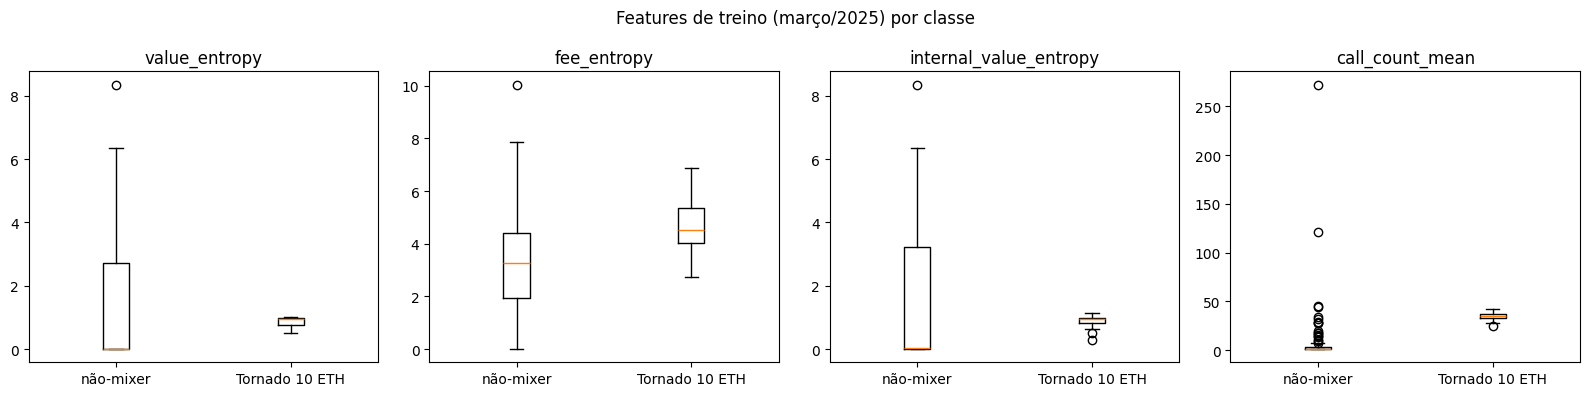

In [56]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, f in zip(axes, FEATURES):
    dados = [treino.loc[treino.label == 0, f], treino.loc[treino.label == 1, f]]
    ax.boxplot(dados)
    ax.set_xticks([1, 2], ["não-mixer", "Tornado 10 ETH"])
    ax.set_title(f)
fig.suptitle("Features de treino (março/2025) por classe")
fig.tight_layout()
fig.savefig(RES/"boxplots_features_treino.png", dpi=150)
plt.show()

---
## Parte C — Treino do Random Forest

**C1 — Validação cruzada estratificada.** Configuração do artigo: 100 árvores, profundidade máxima 5, `class_weight="balanced"`. A reamostragem (oversampling dos positivos) é feita **só dentro do treino de cada fold**, para não inflar as métricas. O artigo não reporta métricas de validação; estas são uma contribuição da reprodução.

In [57]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.utils import resample

def novo_modelo(seed=SEED):
    # configuração do artigo: 100 árvores, profundidade 5, classes balanceadas
    return RandomForestClassifier(n_estimators=100, max_depth=5,
                                  class_weight="balanced", random_state=seed)

def reamostrar(X, y, seed=SEED):
    """Oversampling da classe minoritária até igualar a majoritária (só no treino!)."""
    d = X.assign(_y=y.values)
    maj, mino = d[d._y == 0], d[d._y == 1]
    if len(mino) < len(maj):
        mino = resample(mino, replace=True, n_samples=len(maj), random_state=seed)
    d = pd.concat([maj, mino])
    return d[FEATURES], d["_y"]

X, y = treino[FEATURES], treino["label"]
n_splits = int(min(5, y.sum(), (y == 0).sum()))
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

linhas, cm_total = [], np.zeros((2, 2), dtype=int)
for k, (tr, te) in enumerate(skf.split(X, y), 1):
    Xtr, ytr = reamostrar(X.iloc[tr], y.iloc[tr])
    m = novo_modelo().fit(Xtr, ytr)
    pred = m.predict(X.iloc[te])
    cm_total += confusion_matrix(y.iloc[te], pred, labels=[0, 1])
    linhas.append({"fold": k,
                   "precision": precision_score(y.iloc[te], pred, zero_division=0),
                   "recall": recall_score(y.iloc[te], pred, zero_division=0),
                   "f1": f1_score(y.iloc[te], pred, zero_division=0)})

cv = pd.DataFrame(linhas).set_index("fold")
resumo = cv.agg(["mean", "std"]).rename(index={"mean": "média", "std": "desvio"})
cv = pd.concat([cv, resumo])
cv.to_csv(RES/"cv_metricas.csv")
print(f"Validação cruzada estratificada ({n_splits} folds), {int(y.sum())} positivos / {int((y==0).sum())} negativos")
print("Matriz de confusão somada (linhas = real 0/1, colunas = previsto 0/1):\n", cm_total)
cv.round(3)

Validação cruzada estratificada (5 folds), 23 positivos / 100 negativos
Matriz de confusão somada (linhas = real 0/1, colunas = previsto 0/1):
 [[100   0]
 [  1  22]]


,precision,recall,f1
1,1.0,1.000,1.000
2,1.0,0.800,0.889
3,1.0,1.000,1.000
4,1.0,1.000,1.000
5,1.0,1.000,1.000
média,1.0,0.960,0.978
desvio,0.0,0.089,0.050


**C2 — Modelo final** treinado com todos os dados de março/2025 e salvo no Drive, com a importância de cada feature.

In [58]:
import joblib
Xr, yr = reamostrar(X, y)
modelo = novo_modelo().fit(Xr, yr)
joblib.dump(modelo, PROC/"modelo_rf.joblib")

imp = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values(ascending=False)
imp.to_csv(RES/"importancia_features.csv", header=["importancia"])
print("Modelo salvo em data/processed/modelo_rf.joblib\n")
imp.round(3)

Modelo salvo em data/processed/modelo_rf.joblib



,0
call_count_mean,0.423
value_entropy,0.340
internal_value_entropy,0.221
fee_entropy,0.015


**C3 — Registro das decisões** tomadas neste notebook.

In [59]:
registrar("| 5 | Unidade de classificação | Janela = (endereço destinatário, dia UTC) | Artigo conta 230.658 endereços = destinatários distintos (confirmado no nb 01) | 2026-09-29 |")
registrar(f"| 6 | Mínimo de transações por janela | MIN_TX = {MIN_TX} | Entropia não é informativa com poucas amostras; artigo não especifica | 2026-09-29 |")
registrar(f"| 7 | Cálculo da entropia | Shannon base 2 sobre valores arredondados {DECIMAIS} | Artigo não especifica discretização | 2026-09-29 |")
registrar(f"| 8 | Positivos | Tornado 10 ETH, mar/2025, {'direto + via Router' if INCLUIR_ROUTER else 'só recipient = contrato'} | Filtro por recipient reproduz exatamente os 239 do teste (nb 01) | 2026-09-29 |")
registrar("| 9 | Reamostragem | Oversampling da classe positiva apenas no treino de cada fold | Evita vazamento de dados na validação | 2026-09-29 |")
registrar("| 10 | Negativos | 100 primeiros aceitos na inspeção do Etherscan (02/10/2026); descartados 36, 43 e 144 | Bloqueio por emissor de stablecoin e rótulos de phishing/hack | 2026-10-02 |")
print(dec.read_text())

# Decisões de reprodução

| # | Tema | Decisão | Justificativa | Data |
|---|---|---|---|---|
| 1 | Conjunto de teste | Dump Blockchair `transactions` de 29/10/2020 (dia em UTC) | Mesma fonte e data do artigo | 2026-09-29 |
| 2 | Endereços distintos | sender ∪ recipient, sem vazios (criação de contrato) | Artigo não define; ver `results/sanidade_variantes_20201029.csv` | 2026-09-29 |
| 3 | Transações do Tornado | Filtradas por `recipient` = contrato da instância | Chamadas via proxy/router não aparecem nesta tabela; ver diferença para 239 | 2026-09-29 |
| 4 | Semântica de `call_count`/`internal_value` | No Blockchair incluem a chamada de topo (ver célula 9) | Verificado nos dados; afeta a interpretação das features | 2026-09-29 |
| 5 | Unidade de classificação | Janela = (endereço destinatário, dia UTC) | Artigo conta 230.658 endereços = destinatários distintos (confirmado no nb 01) | 2026-09-29 |
| 6 | Mínimo de transações por janela | MIN_TX = 5 | Entropia não é informativa com pouca

---
## Resultado deste notebook
- `data/processed/features_treino.parquet` e `features_teste_20201029.parquet`
- `data/processed/modelo_rf.joblib`: modelo treinado
- `results/cv_metricas.csv`, `importancia_features.csv`, `boxplots_features_treino.png`

**Próximo:** notebook 04 (classificação de 29/10/2020 e comparação com o artigo).